In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix

# hp = keras_tuner.HyperParameters()

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def test_model(model, dataset):
    y_pred = model.predict(dataset, verbose=0)
    y_true = np.concatenate([y for x, y in dataset], axis=0)
    array = multilabel_confusion_matrix(y_true, y_pred.round())[1]
    return array

In [4]:
train_ds, valid_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_256_train/',
    labels='inferred',
    label_mode='categorical',
    batch_size=16,
    image_size=(256,256),
    validation_split=0.2,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_256_test/',
    labels='inferred',
    label_mode='categorical',
    batch_size=5,
    image_size=(256,256),
    seed=42,
    shuffle=False,
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train_ds = train_ds.map(process)
valid_ds = valid_ds.map(process)
test_ds = test_ds.map(process)

Found 18568 files belonging to 2 classes.
Using 14855 files for training.
Using 3713 files for validation.
Found 4492 files belonging to 2 classes.


In [5]:
model = keras.models.Sequential()
# Correct model
model.add(keras.Input(shape=(256,256,3)))

model.add(layers.Conv2D(filters=32, kernel_size=7, strides=2, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Conv2D(filters=64,kernel_size=3, strides=2, activation='relu', padding='same'))
model.add(layers.Conv2D(filters=64,kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Conv2D(filters=128,kernel_size=3, strides=2, activation='relu', padding='same'))
model.add(layers.Conv2D(filters=128,kernel_size=3, activation='relu', padding='same'))
model.add(layers.Flatten())

model.add(layers.Dense(units=128, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(units=64, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(units=2, activation='softmax'))


model.compile(
        loss=tf.keras.losses.categorical_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        metrics=[keras.metrics.categorical_accuracy]
    )

stop_early = keras.callbacks.EarlyStopping(monitor="val_categorical_accuracy", patience=5)

In [6]:
history = model.fit(
    train_ds, 
    epochs=50,
    validation_data=valid_ds, 
    callbacks=[stop_early],
    class_weight={0: 0.25, 1: 1},
    )

Epoch 1/50
929/929 [==============================] - 43s 42ms/step - loss: 0.1296 - categorical_accuracy: 0.9428 - val_loss: 0.2927 - val_categorical_accuracy: 0.9359
Epoch 2/50
929/929 [==============================] - 38s 40ms/step - loss: 0.1150 - categorical_accuracy: 0.9430 - val_loss: 0.2306 - val_categorical_accuracy: 0.9359
Epoch 3/50
929/929 [==============================] - 38s 41ms/step - loss: 0.1077 - categorical_accuracy: 0.9430 - val_loss: 0.2357 - val_categorical_accuracy: 0.9359
Epoch 4/50
929/929 [==============================] - 38s 41ms/step - loss: 0.1012 - categorical_accuracy: 0.9336 - val_loss: 0.1858 - val_categorical_accuracy: 0.9348
Epoch 5/50
929/929 [==============================] - 39s 42ms/step - loss: 0.0807 - categorical_accuracy: 0.9337 - val_loss: 0.1191 - val_categorical_accuracy: 0.9612
Epoch 6/50
929/929 [==============================] - 41s 44ms/step - loss: 0.0555 - categorical_accuracy: 0.9612 - val_loss: 0.0911 - val_categorical_accuracy:

In [7]:
model.save('./trained_models/model256_cat')

INFO:tensorflow:Assets written to: ./trained_models/model256_cat\assets


INFO:tensorflow:Assets written to: ./trained_models/model256_cat\assets


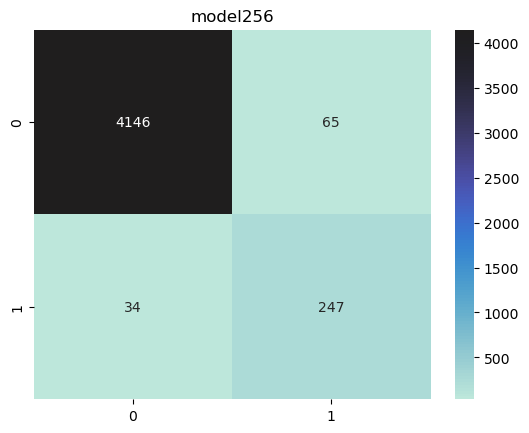

In [9]:
array = test_model(model, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model256')

plt.savefig('./documentation/model256.png')
plt.show()

In [4]:
model256 = keras.models.load_model('./trained_models/model256_test')
model256.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      4736      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 64)        18496     
                                                                 
 conv2d_2 (Conv2D)           (None, 32, 32, 64)        36928     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 16, 16, 64)       0         
 2D)                                                             
                                                                 
 conv2d_3 (Conv2D)           (None, 8, 8, 128)         7

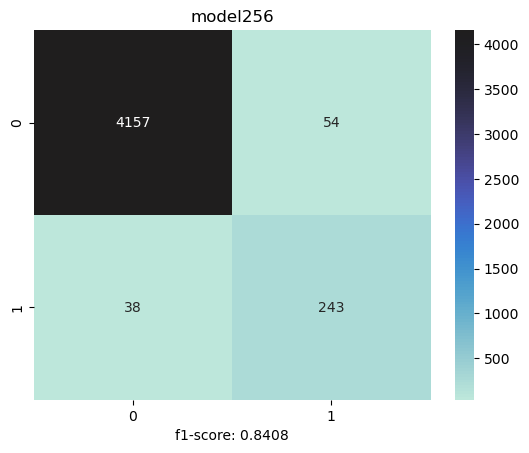

In [6]:
array = test_model(model256, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model256')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.savefig('./documentation/model256.png')
plt.show()